<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_AgIoTIntrusion_Gul2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical neural network for agricultural IoT intrusion detection: Gul & Bakir (2026) step by step

This notebook re-implements, runs and checks the method of

> Muhammed Furkan Gul and Halit Bakir, "A novel metaheuristic-enhanced quantum-classical neural network for attack detection
> in agriculture IoT systems", *The Journal of Supercomputing* 82, article 44, 2026.
> DOI [10.1007/s11227-025-08118-5](https://doi.org/10.1007/s11227-025-08118-5)

The paper publishes no code. Everything below is written from its description. The authors used TensorFlow Quantum (Cirq);
TensorFlow Quantum cannot be installed on a current Colab or Windows Python, so the *same circuit* is simulated here with a small
exact state-vector simulator written in **PyTorch** (12 qubits = 4096 complex amplitudes, exact expectation values, no shot noise,
as in the paper). The circuit is also built in **Qiskit**, drawn, and checked against the simulator amplitude by amplitude.

**What the notebook does.** It downloads the public **Farm-Flow** dataset (network flows of a simulated smart greenhouse with
seven attack types plus normal traffic, Zenodo, CC-BY-4.0), runs the paper's two-stage feature selection (a **binary Starfish
Optimization Algorithm** wrapper around k-NN, then a **mutual-information** top-k filter so that one feature maps to one
qubit), angle-encodes the features with `RY(pi*x)`, applies a three-layer variational circuit (`Rx`, `Rz`, ring of CNOTs),
reads out the Pauli-Z expectation of every qubit and feeds that vector to one of the paper's classical heads. Six models are
trained: **M1** to **M4** (binary: 4-feature hybrid, 12-feature hybrid, qubits + one dense layer, pure quantum) and **M5**,
**M6** (8-class: deep hybrid, shallow hybrid). Random Forest, SVM (RBF) and an MLP are trained on the very same inputs. The
paper's tables and figures are redrawn and compared with the numbers obtained here, claim by claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned packages; if Colab asks to restart the session, restart and run all again. The dataset (about 500 MB zip, public, no login,
nothing gated) is downloaded once into `DATA_DIR`. No GPU, quantum-cloud account or Hugging Face token is needed.

**Runtime.** The committed outputs are from the **full run** (`FAST_MODE = False`, executed locally on a 4-core CPU with 2 PyTorch threads): about **51 minutes** (download of the 500 MB zip not included; classical baselines 3 min, SFOA 0.5 min, training of the six hybrid models 46 min). It uses a pool of 8,000 flows per task (6,000 train + 2,000 validation), 30 epochs, batch 64, learning rate 0.001 as in the paper, three seeds for the classical baselines and one seed for the quantum models. With `FAST_MODE = True` (pool 3,000, 5 epochs, learning rate 0.01) the notebook finishes in about 6 minutes on an idle CPU (a busy or 2-vCPU Colab runtime can take two to three times as long); its accuracies are lower, in particular for the 8-class models. Timing varies a lot with other load on the machine.

**What you get at the end.** Accuracy, precision, recall and F1 with confusion matrices for the six hybrid models and for the
classical baselines, learning curves, the SFOA convergence curves, drawings of the circuits that were actually simulated,
dataset plots (class distributions, labelled 2-D projections) and a verdict per claim of the paper.

## The paper in one page

**Problem.** Detect attacks in the traffic of agricultural IoT (AG-IoT) networks: sensors, actuators and a gateway in a smart
greenhouse speaking MQTT/HTTP/TCP/UDP. Two tasks: **binary** (normal vs attack) and **8-class** (normal + 7 attack types).

**Decision.** A hybrid quantum-classical neural network. Quantum part: angle encoding of 4 or 12 features, a 3-layer parameterised
quantum circuit (PQC) and Pauli-Z read-out; classical part: none, one dense layer, or a small dense stack.

**Data.** Farm-Flow (Ferreira et al., 2025): more than 1.3 million flows, eight attack classes. The authors use the *pre-processed*
version released with the dataset (z-score normalisation, outlier removal, feature engineering, over- and under-sampling) and
split it as in the paper's Table 3: binary train 420,810 / validation 140,271 / test 3,545; multiclass train 303,972 /
validation 101,324 / test 13,091.

**Method.** (1) Binary **SFOA** (Starfish Optimization Algorithm) as a wrapper feature selector: a candidate is a continuous
vector, squashed with a sigmoid and thresholded against a random number to give a binary mask; fitness =
`0.9 * (1 - accuracy of 5-NN) + 0.1 * (selected / all features)`. (2) **Mutual information** (`mutual_info_classif`, 3 neighbours,
training split only) keeps the **top 12** (or top 4) of the SFOA features. (3) Features in [0, 1] -> `RY(pi * x_i)` on qubit *i*.
(4) PQC: 3 layers of `Rz . Rx` on every qubit followed by CNOT entanglement; 24 trainable angles for 12 qubits. (5) `<Z_i>` on
every qubit. (6) Head and training: Adam, learning rate 0.001, batch 64, **30 epochs**, no early stopping, class weights, BCE
(binary) or sparse categorical cross-entropy (multiclass).

**Claims.**

| Model | Task | Features | Head | Accuracy | Recall | Precision | F1 |
|---|---|---|---|---|---|---|---|
| M1 | binary | 4 | Dense(32)+Dropout+Dense(1) | 89.80 | 90.00 | 90.00 | 90.00 |
| **M2** | binary | 12 | Dense(32)+Dropout+Dense(1) | **90.10** | 90.00 | 91.00 | 90.00 |
| M3 | binary | 12 | Dense(1) | 89.50 | 89.00 | 90.00 | 89.00 |
| M4 | binary | 12 | none (mean of `<Z>`, sigmoid) | 88.97 | 89.00 | 91.00 | 89.00 |
| **M5** | 8-class | 12 | Dense(32)+Dense(64)+Dense(8) | **84.60** | 85.00 | 86.00 | 84.00 |
| M6 | 8-class | 12 | Dense(8) | 81.80 | 82.00 | 84.00 | 82.00 |

(Tables 7 and 8.) Further claims: the best classical model of the original Farm-Flow paper reaches 92.67 % (DNN, binary) and
76.37 % (RF, 8-class) so M2 is "competitive" and M5 beats every classical baseline; 12 features beat 4 features (Figs. 4, 5:
validation accuracy 97.9 % vs 99.33 %); M5 reaches 92.4 % validation accuracy (Fig. 7); in the confusion matrices M2 misses
331 of 1771 attacks (1754 of 1774 normal flows correct) and M5 confuses 416 of 673 `Arp_Spoofing` flows with `Normal`; the PQC has
24 trainable parameters; training takes hours on an RTX 3060 (Table 9).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Quantum framework | TensorFlow Quantum + Cirq, state-vector simulation | exact state-vector simulator in PyTorch (same gates, analytic `<Z>`), cross-checked against a Qiskit circuit |
| Data | Farm-Flow, pre-processed version released by Ferreira et al., 1.3 M flows | the four released train/test CSV files of `farm-flow.zip` (Zenodo 10964648). Their sizes match the paper's Table 3 exactly (train + validation 561,081 binary / 405,296 multiclass; test 3,545 / 13,091). |
| Number of input features | SFOA selects ~34 features from the dataset (Table 4); their MI top-12 contain `conn_state`, `flow_duration`, `active.min`, ... | the released CSVs contain only **29** engineered features and none of `conn_state`, `flow_duration`, `active.*`, `idle.*`, so the SFOA and MI stages run on these 29 and select *different* names than Tables 4 and 5 (overlap is reported) |
| Train / validation | 75 : 25 stratified split of the train file | the same, but on a stratified random **pool** of `POOL` rows (CPU budget); the full test files are always used |
| SFOA | 100-agent literature benchmark, population/iterations not given; Algorithm 1 | exploration (Eq. 1, 5 dimensions), preying (Eq. 7-8), regeneration of the last agent (Eq. 9), exploitation/exploration switch with probability 0.5 (as in the original SFOA), greedy replacement, bounds [-4, 4], population and iterations in the configuration; k-NN (k=5) fitness on a held-out part of the pool |
| MI | `mutual_info_classif`, 3 neighbours, training split only | the same, on a random subsample of the training pool (`MI_SAMPLE` rows) |
| Scaling for the circuit | features in [0, 1] | `MinMaxScaler` fitted on the training pool, test clipped to [0, 1] |
| Encoding | `RY(pi * x_i)` | the same |
| PQC | 3 layers `Rz.Rx` + "nearest-neighbour" CNOTs (Eq. 28) or "circular" CNOTs (M3 text) | `Rx` then `Rz` on every qubit, then a **ring** of CNOTs `CNOT(i, i+1 mod n)` applied in order `i = 0..n-1` |
| PQC parameters | 12 qubits and "24 trainable parameters" | one `(Rz, Rx)` angle pair per qubit **shared by the three layers** (this is the only way 3 layers give 24 parameters); random uniform start in [0, 2 pi) |
| Read-out | `<Z_i>` of all qubits | the same (M5/M6: all 12 values go to the dense head, softmax over 8 classes) |
| M5 head | text: Dense(32) then Dense(64) then softmax(8); Table 6 lists 680 parameters, which only fits Dense(32) + Dense(8) | the text version, Dense(32)-Dense(64)-Dense(8) (3,048 classical parameters, so Table 6 cannot be matched) |
| M4 | mean of `<Z>` then sigmoid | `logit = mean(<Z_i>)`, so the output probability lies in [0.27, 0.73] |
| Training | Adam 0.001, batch 64, 30 epochs, class weights, no early stopping | the same in the full run; the quick run uses fewer rows, 5 epochs and learning rate 0.01 |
| Metrics | accuracy, (weighted) recall, precision, F1 | the same, weighted averages (the paper's recall equals its accuracy, which only holds for weighted recall) |
| Classical baselines | DT, LR, NB, RF, DNN from the Farm-Flow paper, trained on all features | quoted from the paper; in addition RF, SVM (RBF) and MLP are re-trained here on the same 12 features and on all 29 |
| Hardware / time | i7-11700 + RTX 3060, 64 GB, 1.5-6 hours per model | shared CPU, minutes; times are therefore not comparable |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): torch 2.14 (CPU), qiskit 2.5.2, scikit-learn 1.x, numpy, pandas, matplotlib.
# Colab already ships torch, numpy, pandas, scikit-learn and matplotlib. The pip line runs on Colab (or wherever Qiskit is
# missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("pylatexenc") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit and pylatexenc already present; skipping pip install.")

qiskit and pylatexenc already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in about 10 minutes. False: the full run described in the "Runtime" paragraph.
SEED      = 42              # CHOICE: the paper does not give a seed
IBM_TOKEN = ""              # not used: the paper simulates on noise-free state vectors, no hardware run

DATA_DIR  = "farmflow_data"
LOCAL_ZIP = ""              # optional: path of an already downloaded farm-flow.zip (skips the download)
ZIP_URLS  = ["https://zenodo.org/api/records/10964648/files/farm-flow.zip/content",
             "https://zenodo.org/records/10964648/files/farm-flow.zip?download=1"]

BATCH     = 64              # paper
N_LAYERS  = 3               # paper: 3 variational layers
DROPOUT   = 0.3             # paper (Case 3)
K_MI      = 3               # paper: mutual_info_classif default, 3 neighbours
N_QUBITS  = 12              # paper: top-12 features -> 12 qubits (M1 uses 4)
VAL_FRAC  = 0.25            # paper: 75 : 25 train / validation split of the train file

if FAST_MODE:
    POOL        = 3000      # CHOICE: training rows drawn from the train file (train + validation together)
    VAL_MAX     = 800       # validation rows scored after every epoch
    EPOCHS      = 5
    LR          = 1e-2      # CHOICE: larger than the paper's 1e-3 because the run has very few updates
    SFOA_POP, SFOA_ITER, SFOA_TRAIN, SFOA_VAL = 8, 8, 2000, 1000
    MI_SAMPLE   = 4000
    SVM_MAX     = 3000
    BASE_SEEDS  = [42]
else:
    POOL        = 8000      # 6,000 train + 2,000 validation rows per task (about 1.5 % of the paper's training data)
    VAL_MAX     = 2000
    EPOCHS      = 30        # paper
    LR          = 1e-3      # paper
    SFOA_POP, SFOA_ITER, SFOA_TRAIN, SFOA_VAL = 10, 15, 4000, 1500
    MI_SAMPLE   = 8000
    SVM_MAX     = 12000
    BASE_SEEDS  = [42, 43, 44]

In [3]:
import os, time, math, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

import torch
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))   # CHOICE: 1-2 threads are fastest for these small matrices
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

print("torch", torch.__version__, "| qiskit", qiskit.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| pool:", POOL, "| epochs:", EPOCHS, "| lr:", LR, "| batch:", BATCH)

torch 2.14.1+cpu | qiskit 2.5.2 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | pool: 8000 | epochs: 30 | lr: 0.001 | batch: 64


## 1. The Farm-Flow data

Farm-Flow (Ferreira et al., *Computers and Electrical Engineering* 121, 109892, 2025; Zenodo record 10964648, CC-BY-4.0) was
captured in a scalable smart-greenhouse testbed (microcontrollers, sensors, actuators, a Raspberry Pi server speaking MQTT/HTTP).
Normal traffic was recorded together with TCP, UDP, MQTT, HTTP and ICMP floods, port scanning and ARP spoofing; the captures were
converted to flows with 100 features. The zip also contains ready-made train/test files for the binary and the 8-class task, already
z-score normalised and class-balanced by the dataset authors; these are the files the paper used (their sizes match the paper's
Table 3), so they are what we load. Each file has 29 numeric features, a `traffic` column (the original class code) and an
`is_attack` column.

`traffic` is an integer code. The released files do not ship the names, but sorting the eight class names alphabetically gives
`Arp_Spoofing=0, HTTP_Flood=1, ICMP_Flood=2, MQTT_Flood=3, Normal=4, Port_scanning=5, TCP_Flood=6, UDP_Flood=7`. The cell below
**verifies** this mapping against the paper's Table 3 (only `Arp_Spoofing` has 673 test flows, `Normal` is the only class with
`is_attack = 0`).

In [4]:
CLASS_NAMES = ["Arp_Spoofing", "HTTP_Flood", "ICMP_Flood", "MQTT_Flood", "Normal", "Port_scanning", "TCP_Flood", "UDP_Flood"]
NORMAL_CODE = 4
FILES = {"bin_train": "Farm-Flow_Train_Binary.csv", "bin_test": "Farm-Flow_Test_Binary.csv",
         "mul_train": "Farm-Flow_Train_Multiclass.csv", "mul_test": "Farm-Flow_Test_Multiclass.csv"}

def get_zip():
    if LOCAL_ZIP and os.path.exists(LOCAL_ZIP):
        return LOCAL_ZIP
    path = os.path.join(DATA_DIR, "farm-flow.zip")
    if os.path.exists(path) and zipfile.is_zipfile(path):
        print("using cached", path); return path
    import requests
    for url in ZIP_URLS:
        try:
            print("downloading", url.split("?")[0], "(about 500 MB) ...")
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(path + ".part", "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 22):
                        f.write(chunk)
            os.replace(path + ".part", path)
            if zipfile.is_zipfile(path):
                return path
        except Exception as e:
            print("failed:", type(e).__name__, e)
    raise RuntimeError("could not download farm-flow.zip; download it from https://zenodo.org/records/10964648 and set LOCAL_ZIP")

zpath = get_zip()
RAW = {}
with zipfile.ZipFile(zpath) as z:
    for key, fn in FILES.items():
        RAW[key] = pd.read_csv(z.open("Datasets/" + fn))
FEATURES = [c for c in RAW["bin_train"].columns if c not in ("is_attack", "traffic")]
for key, df in RAW.items():
    print("%-10s shape %-14s missing=%d  inf=%d" % (key, df.shape, int(df.isna().sum().sum()), int(np.isinf(df[FEATURES].to_numpy()).sum())))

# --- verification of the label mapping against the paper's Table 3 ---------------------------------------------------
bt, bte, mt, mte = RAW["bin_train"], RAW["bin_test"], RAW["mul_train"], RAW["mul_test"]
assert len(bt) == 561081 and len(mt) == 405296                                                        # Table 3: train + validation sizes
assert (bte.loc[bte.traffic == NORMAL_CODE, "is_attack"] == 0).all() and (bte.loc[bte.traffic != NORMAL_CODE, "is_attack"] == 1).all()
assert (bte.traffic == NORMAL_CODE).sum() == 1774 and (bte.is_attack == 1).sum() == 1771          # Table 3, binary test
assert (mte.traffic == 0).sum() == 673 and (mte.traffic == NORMAL_CODE).sum() == 1774 and len(mte) == 13091   # Table 3, multiclass test
assert (bt.traffic == NORMAL_CODE).sum() == 213660 + 71220                                            # Table 3, binary normal train + val
assert (bt.is_attack == 1).sum() == 207150 + 69051                                                    # Table 3, binary attack train + val
print("label mapping and split sizes agree with the paper's Table 3")
print(len(FEATURES), "features:", FEATURES)

using cached farmflow_data\farm-flow.zip


bin_train  shape (561081, 31)   missing=0  inf=0
bin_test   shape (3545, 31)     missing=0  inf=0
mul_train  shape (405296, 31)   missing=0  inf=0


mul_test   shape (13091, 31)    missing=0  inf=0
label mapping and split sizes agree with the paper's Table 3
29 features: ['missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'fwd_iat.tot', 'fwd_iat.avg', 'bwd_iat.tot', 'bwd_iat.avg', 'flow_iat.tot', 'flow_iat.avg', 'pkts_difference', 'data_pkts_difference']


## 2. Pool, train/validation split and test set

The paper trains on 75 % of the released train file and validates on the other 25 % (Table 3). Simulating a 12-qubit circuit for
every one of 420,000 flows and 30 epochs took the authors 6 hours on a GPU, so on a CPU we draw a **stratified random pool** of
`POOL` flows from the train file (stratified by the original class code, so every attack type keeps its share), split it 75 : 25
into train and validation, and always evaluate on the **complete released test file** (3,545 flows binary, 13,091 multiclass).
The label of the binary task is `is_attack`; the label of the 8-class task is `traffic`. For plotting, the binary pool also
remembers the original class code (`family`).

In [5]:
def make_task(train_df, test_df, label, seed):
    pool, _ = train_test_split(train_df, train_size=min(POOL, len(train_df)), stratify=train_df["traffic"], random_state=seed)
    tr, va = train_test_split(pool, test_size=VAL_FRAC, stratify=pool[label], random_state=seed)
    f = lambda d: d[FEATURES].to_numpy(np.float32)
    return dict(Xtr=f(tr), ytr=tr[label].to_numpy().astype(int), ftr=tr["traffic"].to_numpy().astype(int),
                Xva=f(va), yva=va[label].to_numpy().astype(int),
                Xte=f(test_df), yte=test_df[label].to_numpy().astype(int), fte=test_df["traffic"].to_numpy().astype(int))

TASKS = {"binary": make_task(bt, bte, "is_attack", SEED), "multi": make_task(mt, mte, "traffic", SEED)}
for t, D in TASKS.items():
    print("%-7s train %s  validation %s  test %s  | train class counts %s" % (
        t, D["Xtr"].shape, D["Xva"].shape, D["Xte"].shape, dict(zip(*np.unique(D["ytr"], return_counts=True)))))

binary  train (6000, 29)  validation (2000, 29)  test (3545, 29)  | train class counts {np.int64(0): np.int64(3046), np.int64(1): np.int64(2954)}
multi   train (6000, 29)  validation (2000, 29)  test (13091, 29)  | train class counts {np.int64(0): np.int64(30), np.int64(1): np.int64(853), np.int64(2): np.int64(853), np.int64(3): np.int64(853), np.int64(4): np.int64(853), np.int64(5): np.int64(852), np.int64(6): np.int64(853), np.int64(7): np.int64(853)}


## 3. Stage 1 of the feature selection: binary Starfish Optimization Algorithm (SFOA)

SFOA (Zhong et al., 2025) is a population-based metaheuristic that imitates starfish. Each of the `N` agents is a vector in
`[lb, ub]^D` (one coordinate per feature). In every iteration each agent either **explores** (probability 0.5; with `D > 5` it
moves along five random coordinates towards or away from the best agent, Eq. 1-2) or **exploits** (it moves along two of five
distances to the best agent, Eq. 7-8 - the "preying" move); the last agent instead **regenerates** (Eq. 9, `X * exp(-T*N/Tmax)`).
Moves that leave the bounds are rejected (Eq. 4 / 10). To select features, a position is turned into a binary mask: squash with a
sigmoid (Eq. 11) and set the bit if the sigmoid value is at least a uniform random number (Eq. 12). The fitness of a mask is
`0.9 * (1 - accuracy) + 0.1 * (#selected / #features)` (Eq. 13-14) where *accuracy* is that of a 5-nearest-neighbour classifier
trained on the selected columns of a training subsample and scored on a held-out subsample. Lower is better.

The paper does not give population size, iterations, bounds or the exploration probability; ours are in the configuration cell and
marked `# CHOICE:`. The `D <= 5` one-dimensional branch of SFOA (Eq. 5-6) is never used here because `D = 29`. Moves are accepted
only if they improve the agent's fitness (greedy replacement, as in the original SFOA code).

binary  SFOA selected  8 / 29 features, best fitness 0.0366 (population 10, iterations 15)


multi   SFOA selected 11 / 29 features, best fitness 0.2083 (population 10, iterations 15)
SFOA time: 32 s


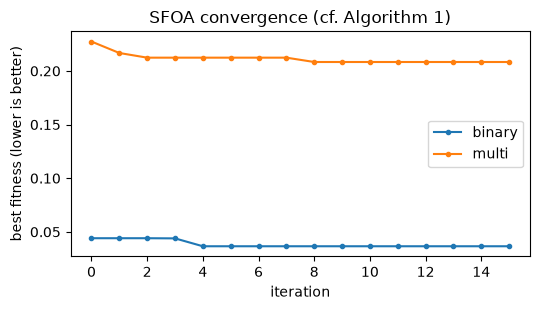

In [6]:
def knn_fitness(mask, Xa, ya, Xb, yb, alpha=0.90, beta=0.10):
    """Eq. 13-14: alpha * error rate (5-NN, held-out) + beta * selected / all features."""
    cols = np.flatnonzero(mask)
    if cols.size == 0:
        return 1.0
    knn = KNeighborsClassifier(n_neighbors=5).fit(Xa[:, cols], ya)
    err = 1.0 - float((knn.predict(Xb[:, cols]) == yb).mean())
    return alpha * err + beta * cols.size / mask.size

def binarise(x, gen):
    """Eq. 11-12: sigmoid, then compare with a uniform random number; force at least one feature."""
    b = (1.0 / (1.0 + np.exp(-x))) >= gen.random(x.shape)
    if not b.any():
        b[gen.integers(x.size)] = True
    return b

def sfoa_select(Xa, ya, Xb, yb, pop, iters, seed, lb=-4.0, ub=4.0, gp=0.5):
    # CHOICE: lb/ub = [-4, 4], gp = 0.5 (exploration probability of the original SFOA), greedy replacement
    gen = np.random.default_rng(seed)
    D = Xa.shape[1]
    X = gen.uniform(lb, ub, (pop, D))
    masks = [binarise(x, gen) for x in X]
    fit = np.array([knn_fitness(m, Xa, ya, Xb, yb) for m in masks])
    history = [fit.min()]
    for T in range(1, iters + 1):
        best = X[np.argmin(fit)].copy()
        theta = (math.pi / 2) * T / iters                                   # Eq. 3
        for i in range(pop):
            r = gen.random()
            if i == pop - 1:                                                # regeneration, Eq. 9 (last agent only)
                Y = np.exp(-T * pop / iters) * X[i]
            elif gen.random() > gp:                                         # exploration, Eq. 1 (D > 5: five dimensions)
                Y = X[i].copy()
                p = gen.choice(D, size=5, replace=False)
                a1 = (2 * gen.random() - 1) * math.pi                       # Eq. 2
                if r <= 0.5:
                    Y[p] = X[i, p] + a1 * (best[p] - X[i, p]) * math.cos(theta)
                else:
                    Y[p] = X[i, p] - a1 * (best[p] - X[i, p]) * math.sin(theta)
                if np.any((Y < lb) | (Y > ub)):                             # Eq. 4: stay where you were if out of bounds
                    Y = X[i].copy()
            else:                                                           # preying / exploitation, Eq. 7-8
                mp = gen.choice(pop, size=5, replace=False)
                d = best[None, :] - X[mp]
                m1, m2 = gen.choice(5, size=2, replace=False)
                Y = X[i] + gen.random() * d[m1] + gen.random() * d[m2]
                Y = np.clip(Y, lb, ub)                                      # Eq. 10
            mY = binarise(Y, gen)
            fY = knn_fitness(mY, Xa, ya, Xb, yb)
            if fY < fit[i]:
                X[i], fit[i], masks[i] = Y, fY, mY
        history.append(fit.min())
    k = int(np.argmin(fit))
    return masks[k], float(fit[k]), history

SFOA = {}
t0 = time.time()
for task in ("binary", "multi"):
    D = TASKS[task]
    sub = np.random.default_rng(SEED).permutation(len(D["Xtr"]))
    a_idx = sub[:min(SFOA_TRAIN, len(sub))]
    b_idx = np.random.default_rng(SEED + 1).permutation(len(D["Xva"]))[:SFOA_VAL]       # held-out part: validation rows
    mask, f, hist = sfoa_select(D["Xtr"][a_idx], D["ytr"][a_idx], D["Xva"][b_idx], D["yva"][b_idx], SFOA_POP, SFOA_ITER, SEED)
    SFOA[task] = dict(mask=mask, fitness=f, history=hist)
    print("%-7s SFOA selected %2d / %d features, best fitness %.4f (population %d, iterations %d)" % (
        task, mask.sum(), len(FEATURES), f, SFOA_POP, SFOA_ITER))
print("SFOA time: %.0f s" % (time.time() - t0))

fig, ax = plt.subplots(figsize=(5.5, 3.2))
for task, D_ in SFOA.items():
    ax.plot(D_["history"], marker="o", ms=3, label=task)
ax.set_xlabel("iteration"); ax.set_ylabel("best fitness (lower is better)"); ax.set_title("SFOA convergence (cf. Algorithm 1)")
ax.legend(); fig.tight_layout(); plt.show()

## 4. Stage 2: mutual-information top-k

Quantum simulators need one qubit per feature, so the paper keeps the **12** SFOA-selected features with the largest mutual
information with the label (and, for model M1, the top **4**). `mutual_info_classif` is used with its defaults (3 neighbours) and
only on training rows. If SFOA happens to keep fewer than 12 features we top up with the best-ranked unselected features so that
the circuit still has 12 qubits (`# CHOICE:`); this is printed when it happens.

In [7]:
PAPER_TABLE4 = ["fwd_pkts_payload.tot", "flow_iat.std", "idle.std", "bwd_pkts_payload.std", "bwd_iat.tot", "fwd_iat.max",
                "flow_pkts_payload.tot", "active.std", "bwd_PSH_flag_count", "fwd_pkts_payload.min", "active.min", "orig_ip_bytes",
                "bwd_header_size_max", "fwd_header_size_min", "idle.min", "fwd_bulk_packets", "bwd_bulk_bytes", "bwd_bulk_rate",
                "fwd_pkts_per_sec", "conn_state", "idle.tot", "flow_pkts_per_sec", "fwd_bulk_bytes", "active.max", "bwd_iat.min",
                "flow_ACK_flag_count", "bwd_pkts_payload.max", "flow_duration", "fwd_bulk_rate", "flow_pkts_payload.avg",
                "fwd_subflow_pkts", "fwd_header_size_max", "data_pkts_difference", "flow_iat.tot", "fwd_PSH_flag_count"]
PAPER_TABLE5 = {"binary12": ["conn_state", "orig_ip_bytes", "flow_duration", "fwd_pkts_per_sec", "flow_pkts_per_sec",
                             "fwd_pkts_payload.tot", "flow_pkts_payload.tot", "fwd_iat.max", "flow_iat.std", "fwd_subflow_pkts",
                             "active.min", "active.max"],
                "binary4": ["orig_ip_bytes", "flow_pkts_per_sec", "active.min", "active.max"],
                "multi12": ["conn_state", "orig_ip_bytes", "flow_duration", "fwd_pkts_per_sec", "flow_pkts_per_sec",
                            "fwd_header_size_min", "fwd_header_size_max", "bwd_header_size_max", "flow_ACK_flag_count",
                            "flow_iat.tot", "active.min", "active.max"]}

def mi_topk(task, k):
    D = TASKS[task]
    sel = np.flatnonzero(SFOA[task]["mask"])
    idx = np.random.default_rng(SEED).permutation(len(D["Xtr"]))[:MI_SAMPLE]
    mi_all = mutual_info_classif(D["Xtr"][idx], D["ytr"][idx], n_neighbors=K_MI, random_state=SEED)
    order = [j for j in np.argsort(-mi_all) if j in set(sel)]
    if len(order) < k:
        extra = [j for j in np.argsort(-mi_all) if j not in set(sel)][:k - len(order)]
        print("  (%s: SFOA kept only %d features, topping up with %s)" % (task, len(order), [FEATURES[j] for j in extra]))
        order += extra
    return np.array(order[:k]), mi_all

SELECT = {}
for key, task, k in [("binary12", "binary", 12), ("binary4", "binary", 4), ("multi12", "multi", 12)]:
    cols, mi_all = mi_topk(task, k)
    SELECT[key] = dict(task=task, cols=cols, names=[FEATURES[j] for j in cols], mi=mi_all[cols])
    ov = len(set(SELECT[key]["names"]) & set(PAPER_TABLE5[key]))
    print("%-9s top-%d: %s\n          overlap with the paper's Table 5 list: %d of %d (the released CSVs lack most of the paper's names)" % (
        key, k, SELECT[key]["names"], ov, k))
sf_names = [FEATURES[j] for j in np.flatnonzero(SFOA["binary"]["mask"])]
print("\nbinary SFOA subset (%d): %s" % (len(sf_names), sf_names))
print("names shared with the paper's Table 4:", sorted(set(sf_names) & set(PAPER_TABLE4)))

  (binary: SFOA kept only 8 features, topping up with ['orig_ip_bytes', 'orig_pkts', 'flow_iat.avg', 'flow_iat.tot'])
binary12  top-12: ['fwd_iat.tot', 'fwd_iat.avg', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'bwd_header_size_max', 'bwd_pkts_payload.avg', 'data_pkts_difference', 'flow_pkts_payload.avg', 'orig_ip_bytes', 'orig_pkts', 'flow_iat.avg', 'flow_iat.tot']
          overlap with the paper's Table 5 list: 2 of 12 (the released CSVs lack most of the paper's names)


binary4   top-4: ['fwd_iat.tot', 'fwd_iat.avg', 'bwd_pkts_per_sec', 'flow_pkts_per_sec']
          overlap with the paper's Table 5 list: 1 of 4 (the released CSVs lack most of the paper's names)


  (multi: SFOA kept only 11 features, topping up with ['fwd_header_size_tot'])
multi12   top-12: ['orig_ip_bytes', 'fwd_header_size_max', 'fwd_header_size_min', 'resp_ip_bytes', 'bwd_header_size_tot', 'bwd_header_size_min', 'flow_iat.tot', 'orig_pkts', 'missed_bytes', 'fwd_pkts_payload.avg', 'flow_pkts_payload.tot', 'fwd_header_size_tot']
          overlap with the paper's Table 5 list: 4 of 12 (the released CSVs lack most of the paper's names)

binary SFOA subset (8): ['bwd_pkts_per_sec', 'flow_pkts_per_sec', 'bwd_header_size_max', 'bwd_pkts_payload.avg', 'flow_pkts_payload.avg', 'fwd_iat.tot', 'fwd_iat.avg', 'data_pkts_difference']
names shared with the paper's Table 4: ['bwd_header_size_max', 'data_pkts_difference', 'flow_pkts_payload.avg', 'flow_pkts_per_sec']


## 5. Scaling to [0, 1] and the three input sets

The circuit angle is `pi * x` with `x` in [0, 1]. A `MinMaxScaler` is fitted **on the training pool only** for each of the three
feature sets (`binary4`, `binary12`, `multi12`); validation and test values are clipped to [0, 1]. The released data are already
z-scored, so the scaler only squeezes the (clipped) tails.

In [8]:
INPUTS = {}
for key, S in SELECT.items():
    D = TASKS[S["task"]]
    sc = MinMaxScaler().fit(D["Xtr"][:, S["cols"]])
    g = lambda X: np.clip(sc.transform(X[:, S["cols"]]), 0.0, 1.0).astype(np.float32)
    INPUTS[key] = dict(Xtr=g(D["Xtr"]), Xva=g(D["Xva"]), Xte=g(D["Xte"]))
    I = INPUTS[key]
    print("%-9s train %s val %s test %s | train range [%.2f, %.2f] | share of test values clipped at 0 or 1: %.1f %%" % (
        key, I["Xtr"].shape, I["Xva"].shape, I["Xte"].shape, I["Xtr"].min(), I["Xtr"].max(),
        100 * np.mean((g(D["Xte"]) == 0) | (g(D["Xte"]) == 1))))

binary12  train (6000, 12) val (2000, 12) test (3545, 12) | train range [0.00, 1.00] | share of test values clipped at 0 or 1: 35.0 %
binary4   train (6000, 4) val (2000, 4) test (3545, 4) | train range [0.00, 1.00] | share of test values clipped at 0 or 1: 38.1 %
multi12   train (6000, 12) val (2000, 12) test (13091, 12) | train range [0.00, 1.00] | share of test values clipped at 0 or 1: 47.4 %


## Dataset Exploration and Visualisation

Everything in this section is drawn from the **real flows** of the Farm-Flow files (no synthetic data). First the shape, feature
names and the original labels with their counts, then the class distributions as bar charts, then labelled 2-D projections: the raw
PCA coordinates of the 12 selected features (PCA fitted on the training pool only) and the same coordinates mapped to [0, pi]
like the circuit's rotation angles, coloured by the **original attack class** (in the binary plot as well, so the attack types
stay visible).

In [9]:
print("Released files:")
for key, df in RAW.items():
    print("  %-10s shape %s" % (key, df.shape))
print("\nfeature names (%d):" % len(FEATURES)); print(FEATURES)
print("\noriginal label values: traffic code -> name:", dict(enumerate(CLASS_NAMES)), "| is_attack: 0 = Normal, 1 = any attack")
cnt = pd.DataFrame({
    "class": CLASS_NAMES,
    "binary train+val (file)": [int((bt.traffic == c).sum()) for c in range(8)],
    "binary test": [int((bte.traffic == c).sum()) for c in range(8)],
    "multiclass train+val (file)": [int((mt.traffic == c).sum()) for c in range(8)],
    "multiclass test": [int((mte.traffic == c).sum()) for c in range(8)],
    "pool train (multi)": [int((TASKS["multi"]["ytr"] == c).sum()) for c in range(8)],
    "pool val (multi)": [int((TASKS["multi"]["yva"] == c).sum()) for c in range(8)]})
display(cnt)
print("binary labels (file, train+val): Normal %d, Attack %d | test: Normal %d, Attack %d | pool train: %s" % (
    (bt.is_attack == 0).sum(), (bt.is_attack == 1).sum(), (bte.is_attack == 0).sum(), (bte.is_attack == 1).sum(),
    dict(zip(*np.unique(TASKS['binary']['ytr'], return_counts=True)))))
print("\nfirst rows of the binary test file (selected binary12 features):")
display(bte[SELECT["binary12"]["names"] + ["traffic", "is_attack"]].head())

Released files:
  bin_train  shape (561081, 31)
  bin_test   shape (3545, 31)
  mul_train  shape (405296, 31)
  mul_test   shape (13091, 31)

feature names (29):
['missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'fwd_iat.tot', 'fwd_iat.avg', 'bwd_iat.tot', 'bwd_iat.avg', 'flow_iat.tot', 'flow_iat.avg', 'pkts_difference', 'data_pkts_difference']

original label values: traffic code -> name: {0: 'Arp_Spoofing', 1: 'HTTP_Flood', 2: 'ICMP_Flood', 3: 'MQTT_Flood', 4: 'Normal', 5: 'Port_scanning', 6: 'TCP_Flood', 7: 'UDP_Flood'} | is_attack: 0 = Normal, 1 = any attack


,class,binary train+val (file),binary test,multiclass train+val (file),multiclass test,pool train (multi),pool val (multi)
0,Arp_Spoofing,2019,253,2019,673,30,10
1,HTTP_Flood,45697,253,57611,1774,853,285
2,ICMP_Flood,45697,253,57611,1774,853,284
3,MQTT_Flood,45697,253,57611,1774,853,284
4,Normal,284880,1774,57611,1774,853,284
5,Port_scanning,45697,253,57611,1774,852,285
6,TCP_Flood,45697,253,57611,1774,853,284
7,UDP_Flood,45697,253,57611,1774,853,284


binary labels (file, train+val): Normal 284880, Attack 276201 | test: Normal 1774, Attack 1771 | pool train: {np.int64(0): np.int64(3046), np.int64(1): np.int64(2954)}

first rows of the binary test file (selected binary12 features):


,fwd_iat.tot,fwd_iat.avg,bwd_pkts_per_sec,flow_pkts_per_sec,bwd_header_size_max,bwd_pkts_payload.avg,data_pkts_difference,flow_pkts_payload.avg,orig_ip_bytes,orig_pkts,flow_iat.avg,flow_iat.tot,traffic,is_attack
0,-0.118951,-0.158987,0.001200,0.001200,2.459743,0.554383,0.293208,-0.000945,2.696519,1.352744,-0.161982,-0.115159,0,1.0
1,-0.159274,-0.168324,0.003931,0.003931,0.289254,6.171087,-0.013989,-0.000945,2.696519,1.352744,-0.165631,-0.156242,0,1.0
2,-0.158983,-0.168172,0.009950,0.009950,0.289254,6.171087,-0.013989,-0.000945,0.113241,0.405725,-0.166681,-0.160720,0,1.0
3,-0.158742,-0.168046,0.003083,0.003083,0.289254,6.171087,-0.013989,-0.000945,0.113241,0.405725,-0.165154,-0.154204,0,1.0
4,0.690850,-0.041358,0.000103,0.000103,1.374499,1.844707,0.242008,-0.000945,2.696519,1.352744,-0.105526,0.686271,0,1.0


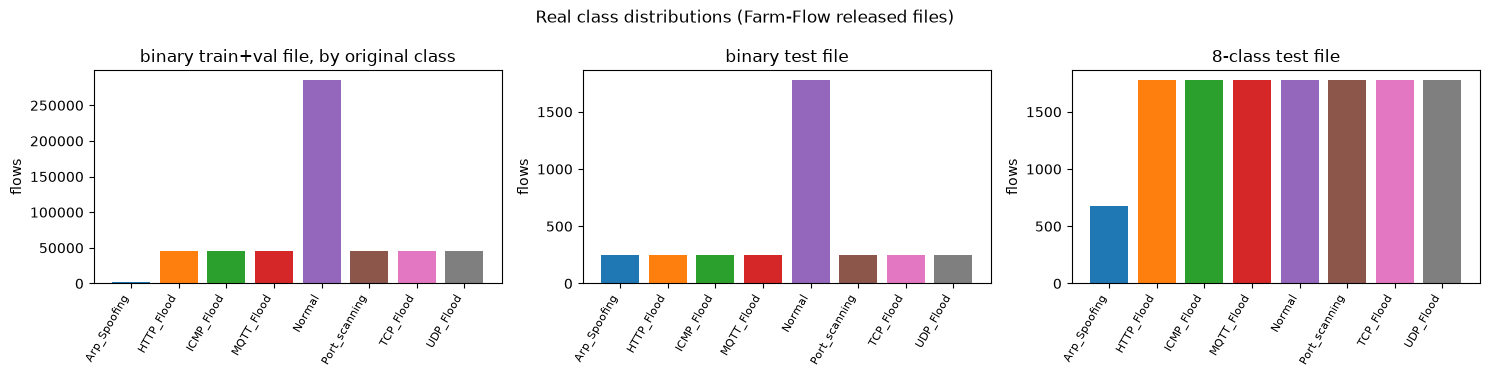

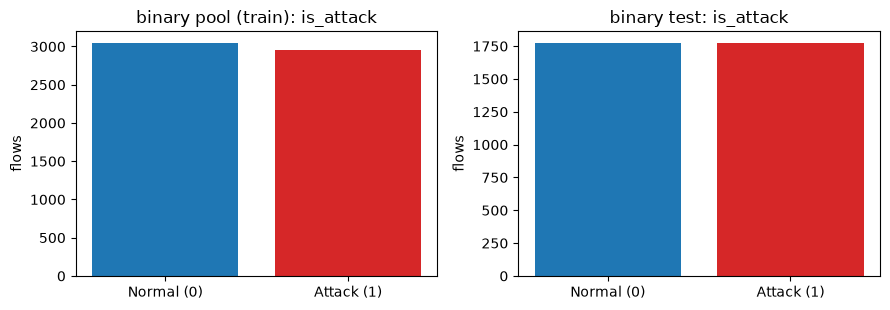

In [10]:
colours = plt.cm.tab10(np.arange(8))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, ser) in zip(axes, [("binary train+val file, by original class", bt.traffic), ("binary test file", bte.traffic),
                                    ("8-class test file", mte.traffic)]):
    vc = ser.value_counts().reindex(range(8)).fillna(0)
    ax.bar(range(8), vc.values, color=colours)
    ax.set_xticks(range(8)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right", fontsize=8)
    ax.set_title(title); ax.set_ylabel("flows")
fig.suptitle("Real class distributions (Farm-Flow released files)"); fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (title, y) in zip(axes, [("binary pool (train)", TASKS["binary"]["ytr"]), ("binary test", TASKS["binary"]["yte"])]):
    vc = np.bincount(y, minlength=2)
    ax.bar(["Normal (0)", "Attack (1)"], vc, color=["tab:blue", "tab:red"]); ax.set_title(title + ": is_attack"); ax.set_ylabel("flows")
fig.tight_layout(); plt.show()

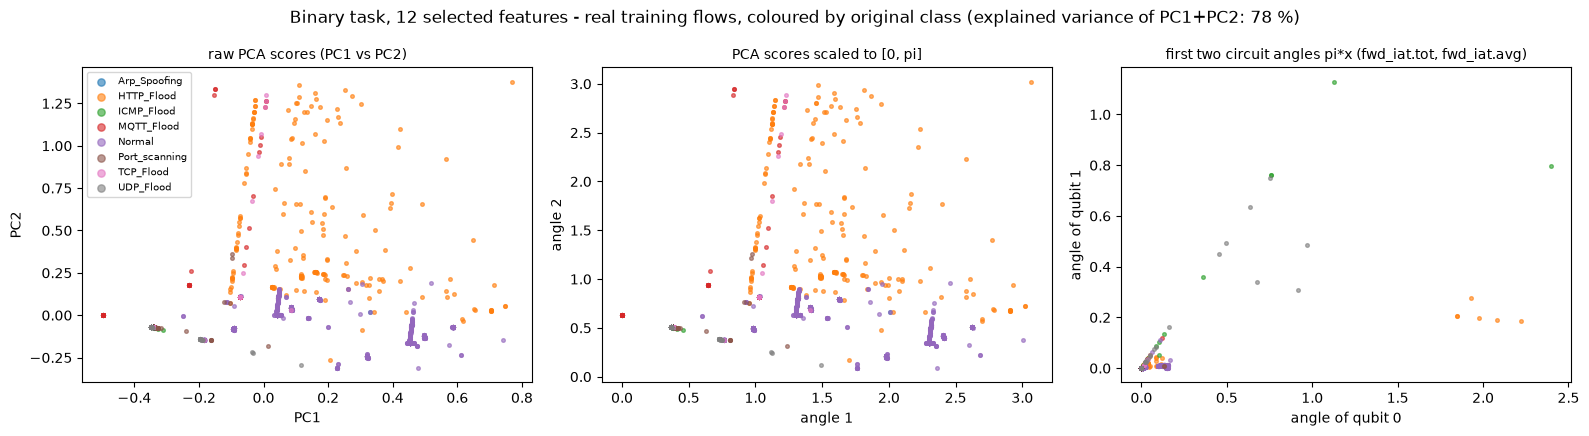

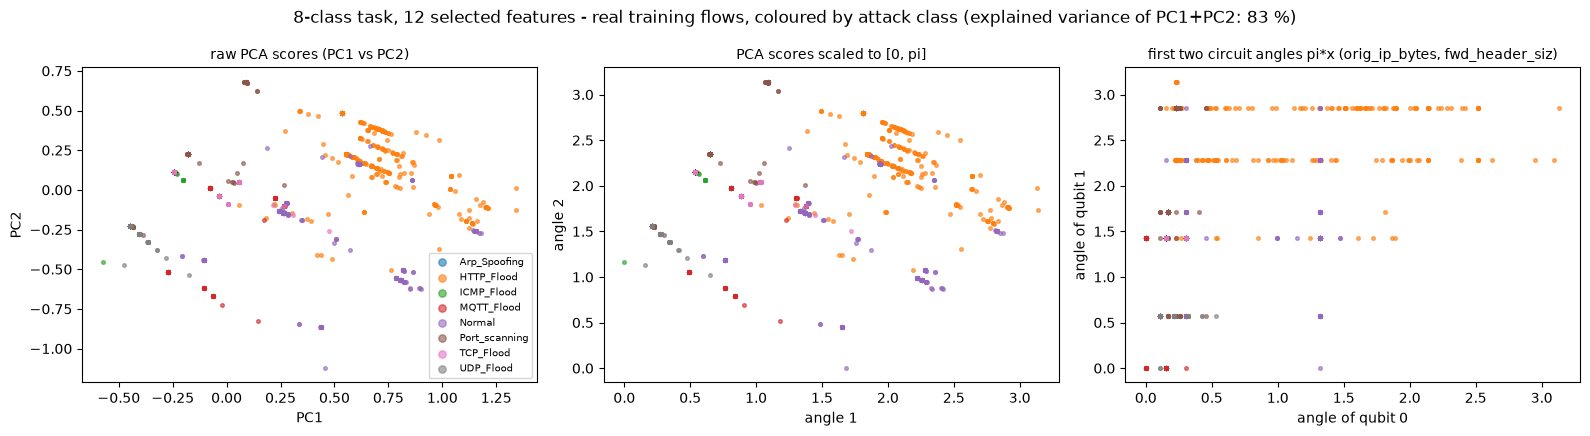

In [11]:
def pca_scatter(key, task, max_pts=2500, title=""):
    """Two views of the real training flows: raw PCA scores and the same scores scaled to [0, pi]."""
    I, D = INPUTS[key], TASKS[task]
    pca = PCA(n_components=2, random_state=SEED).fit(I["Xtr"])                  # fitted on the training pool only
    Z = pca.transform(I["Xtr"])
    ang = MinMaxScaler((0, np.pi)).fit(Z).transform(Z)                          # CHOICE: scaled like the reference notebooks
    idx = np.random.default_rng(SEED).permutation(len(Z))[:max_pts]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    views = [(Z, "raw PCA scores (PC1 vs PC2)", "PC1", "PC2"), (ang, "PCA scores scaled to [0, pi]", "angle 1", "angle 2"),
             (np.pi * I["Xtr"][:, :2], "first two circuit angles pi*x (%s, %s)" % tuple(n[:14] for n in SELECT[key]["names"][:2]),
              "angle of qubit 0", "angle of qubit 1")]
    for ax, (P, ttl, xl, yl) in zip(axes, views):
        for c in range(8):
            m = D["ftr"][idx] == c
            if m.any():
                ax.scatter(P[idx][m, 0], P[idx][m, 1], s=7, alpha=.6, color=colours[c], label=CLASS_NAMES[c])
        ax.set_title(ttl, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)
    axes[0].legend(markerscale=2, fontsize=7, loc="best")
    fig.suptitle(title + " (explained variance of PC1+PC2: %.0f %%)" % (100 * pca.explained_variance_ratio_.sum()))
    fig.tight_layout(); plt.show()

pca_scatter("binary12", "binary", title="Binary task, 12 selected features - real training flows, coloured by original class")
pca_scatter("multi12", "multi", title="8-class task, 12 selected features - real training flows, coloured by attack class")

## Quantum Circuit Architecture

All six models share one parameterised quantum circuit (PQC), built here in Qiskit from the paper's description:

1. **Encoding.** `RY(pi * x_i)` on qubit *i* for each of the *n* features (Eq. 25-26).
2. **Variational layer, repeated 3 times.** On every qubit `Rx(phi_i)` then `Rz(theta_i)` (Eq. 27, `Rz . Rx`), followed by a ring of
   CNOTs `CNOT(0,1), CNOT(1,2), ..., CNOT(n-1,0)` (Eq. 28; "circular" in the M3 text).
3. **Read-out.** `<Z_i>` of every qubit (exact expectation values).

*Assumptions where the paper is silent:* the paper's Fig. 3 is not machine readable, so the gate order inside a layer follows
Eq. 27 and the CNOT ring follows the M3 description; to obtain the stated **24 trainable parameters for 12 qubits** with three
layers, the angles `(theta_i, phi_i)` are shared across the layers (the circuit therefore repeats the same layer 3 times);
initial angles are uniform in [0, 2 pi).

The drawing below is the circuit built by `build_qiskit_pqc`. The training code uses an exact PyTorch state-vector simulator
that applies the same gates; the cell after the drawings **asserts** that the simulator and Qiskit give the same `<Z_i>` for
random inputs and angles. There is one distinct architecture per qubit count: 12 qubits (M2-M6) and 4 qubits (M1). The classical heads
(dense layers, dropout, softmax) are listed in Section 7.

12-qubit PQC: qubits = 12 | depth = 43 | gates = {'rx': 36, 'rz': 36, 'cx': 36, 'ry': 12, 'barrier': 4} | trainable parameters = 24 (12 angles Rz + 12 angles Rx, shared by the 3 layers) | data inputs = 12


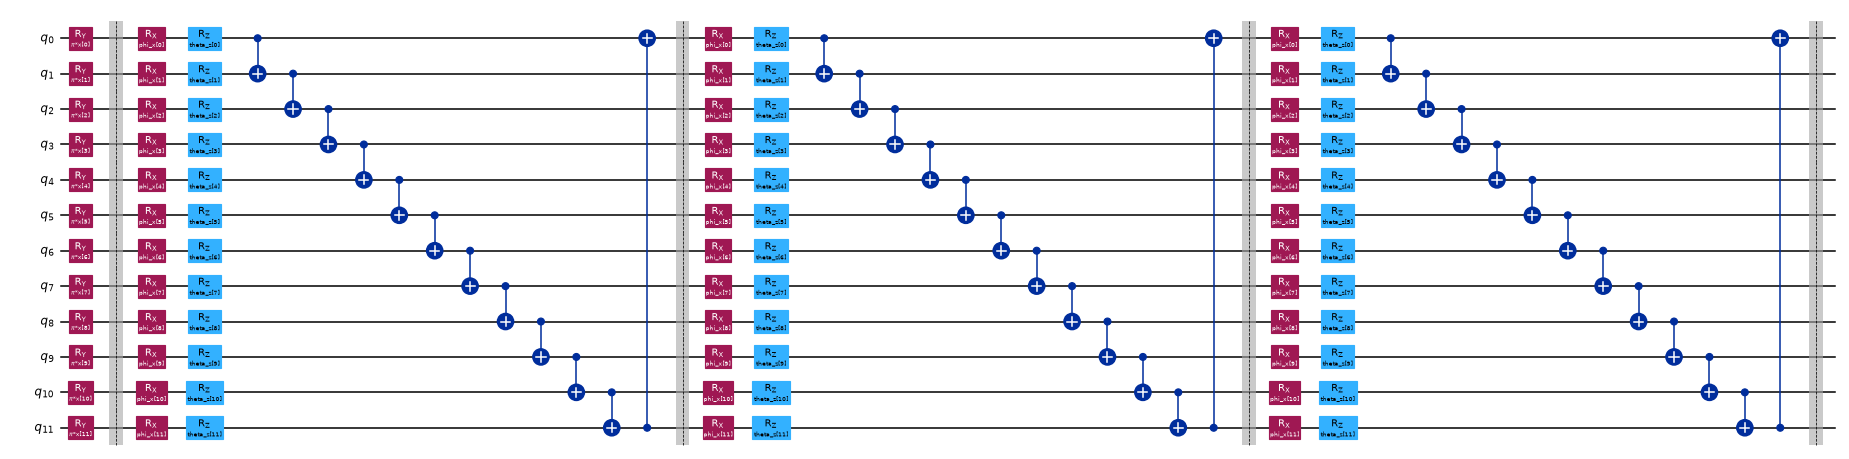

 4-qubit PQC: qubits = 4 | depth = 19 | gates = {'rx': 12, 'rz': 12, 'cx': 12, 'ry': 4, 'barrier': 4} | trainable parameters = 8 (4 angles Rz + 4 angles Rx, shared by the 3 layers) | data inputs = 4


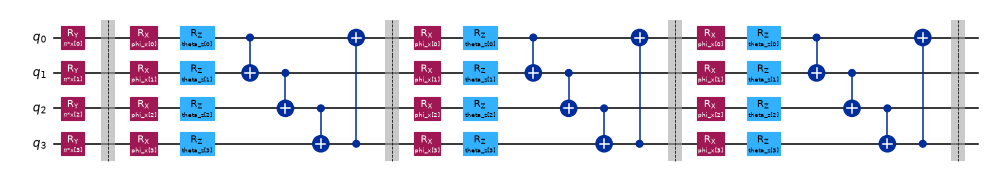

with read-out: 12-qubit PQC + measurement of every qubit has depth 44 (<Z_i> is computed exactly from the state vector, no shots)


In [12]:
def build_qiskit_pqc(n, layers=N_LAYERS, measure=False):
    x = ParameterVector("x", n); th = ParameterVector("theta_z", n); ph = ParameterVector("phi_x", n)
    qc = QuantumCircuit(n, name="PQC_%dq" % n)
    for i in range(n):
        qc.ry(np.pi * x[i], i)                         # angle encoding, Eq. 25
    qc.barrier()
    for _ in range(layers):
        for i in range(n):
            qc.rx(ph[i], i); qc.rz(th[i], i)           # Rz . Rx, Eq. 27 (Rx acts first)
        for i in range(n):
            qc.cx(i, (i + 1) % n)                      # ring of CNOTs, Eq. 28
        qc.barrier()
    if measure:
        qc.measure_all()
    return qc, x, th, ph

for n in (12, 4):
    qc, x, th, ph = build_qiskit_pqc(n)
    print("%2d-qubit PQC: qubits = %d | depth = %d | gates = %s | trainable parameters = %d (%d angles Rz + %d angles Rx, shared by the %d layers) | data inputs = %d" % (
        n, qc.num_qubits, qc.depth(), dict(qc.count_ops()), len(th) + len(ph), len(th), len(ph), N_LAYERS, len(x)))
    display(qc.draw("mpl", fold=110, scale=0.55))
qc12 = build_qiskit_pqc(12, measure=True)[0]
print("with read-out: 12-qubit PQC + measurement of every qubit has depth", qc12.depth(), "(<Z_i> is computed exactly from the state vector, no shots)")

### The simulator used for training, and the check against Qiskit

`PQC` below stores the state of a batch of samples as an array of `2^n` complex amplitudes. The product state after the `RY`
encoding is built by outer products; each variational layer multiplies the state by the tensor product of the `Rz.Rx` matrices of
four qubits at a time (three 16 x 16 matrix products for 12 qubits) and then permutes the amplitudes according to the CNOT ring;
`<Z_i>` is obtained from the probabilities. Gradients come from PyTorch autograd, which is exactly the gradient TensorFlow Quantum
computes with its adjoint/back-propagation differentiators on a noise-free simulator.

In [13]:
def ring_perm(n):
    f = np.arange(2 ** n)
    for i in range(n):                                  # apply CNOT(i, i+1 mod n) to every basis state, in order
        f = f ^ (((f >> (n - 1 - i)) & 1) << (n - 1 - (i + 1) % n))
    inv = np.empty_like(f); inv[f] = np.arange(2 ** n)
    return torch.as_tensor(inv, dtype=torch.long)

class PQC(torch.nn.Module):
    """Exact state-vector simulation of the paper's circuit; qubit 0 is the most significant bit of the amplitude index."""
    def __init__(self, n, layers=N_LAYERS, seed=0):
        super().__init__()
        assert n % 4 == 0
        g = torch.Generator().manual_seed(seed)
        self.n, self.L, self.G = n, layers, n // 4
        self.theta = torch.nn.Parameter(torch.rand(2, n, generator=g) * 2 * math.pi)     # row 0: Rz angles, row 1: Rx angles
        self.register_buffer("perm", ring_perm(n))
        signs = np.array([[1 - 2 * ((b >> (n - 1 - i)) & 1) for i in range(n)] for b in range(2 ** n)], dtype=np.float32)
        self.register_buffer("zs", torch.as_tensor(signs))
    def one_qubit(self):
        tz, tx = self.theta[0], self.theta[1]
        c, s = torch.cos(tx / 2), torch.sin(tx / 2)
        rx = torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
        e = torch.exp(-0.5j * tz); z0 = torch.zeros_like(e)
        rz = torch.stack([torch.stack([e, z0], -1), torch.stack([z0, e.conj()], -1)], -2)
        return rz @ rx                                                                      # Rx first, then Rz
    def forward(self, x):                                                                   # x in [0, 1], shape (B, n)
        B, n = x.shape
        a = torch.stack([torch.cos(math.pi * x / 2), torch.sin(math.pi * x / 2)], -1)       # RY(pi x)|0>
        s = a[:, 0]
        for i in range(1, n):
            s = (s[:, :, None] * a[:, i][:, None, :]).reshape(B, -1)
        s = s.to(torch.complex64)
        M = self.one_qubit(); Ks = []
        for g in range(self.G):
            K = M[4 * g]
            for j in range(4 * g + 1, 4 * g + 4):
                K = torch.kron(K, M[j])
            Ks.append(K.T.contiguous())
        for _ in range(self.L):
            for k in reversed(range(self.G)):                                               # blocks of four qubits
                s = torch.matmul(s.reshape(-1, 16), Ks[k])
                if self.G > 1:
                    s = s.reshape(B, *([16] * self.G)).movedim(-1, 1).reshape(B, -1)
            s = s.reshape(B, -1)[:, self.perm]                                              # CNOT ring
        p = s.real ** 2 + s.imag ** 2
        return p @ self.zs                                                                  # <Z_i>, shape (B, n)

def qiskit_expectations(n, xs, theta_z, phi_x):
    qc, x, th, ph = build_qiskit_pqc(n)
    out = []
    for xv in xs:
        bind = {**{x[i]: float(xv[i]) for i in range(n)}, **{th[i]: float(theta_z[i]) for i in range(n)},
                **{ph[i]: float(phi_x[i]) for i in range(n)}}
        sv = Statevector(qc.assign_parameters(bind))
        out.append([sv.expectation_value(SparsePauliOp.from_sparse_list([("Z", [i], 1.0)], num_qubits=n)).real for i in range(n)])
    return np.array(out)

def check_against_qiskit(sim, n, xs):
    with torch.no_grad():
        mine = sim(torch.tensor(xs, dtype=torch.float32)).numpy()
    ref = qiskit_expectations(n, xs, sim.theta[0].detach().numpy(), sim.theta[1].detach().numpy())
    err = np.abs(mine - ref).max()
    assert err < 1e-4, "simulator and Qiskit disagree: max error %.2e" % err
    return err

for n in (4, 12):
    sim = PQC(n, seed=123)
    xs = np.random.default_rng(0).random((5, n)).astype(np.float32)
    print("n = %2d qubits: max |<Z_i>(simulator) - <Z_i>(Qiskit)| over 5 random inputs = %.1e  (assertion < 1e-4 passed)" % (n, check_against_qiskit(sim, n, xs)))

n =  4 qubits: max |<Z_i>(simulator) - <Z_i>(Qiskit)| over 5 random inputs = 2.4e-07  (assertion < 1e-4 passed)


n = 12 qubits: max |<Z_i>(simulator) - <Z_i>(Qiskit)| over 5 random inputs = 1.1e-07  (assertion < 1e-4 passed)


## 6. Classical baselines on identical inputs

The paper quotes classical results from the Farm-Flow paper (trained on all features). We quote those too, but also re-train three
classical models **on exactly the inputs of the quantum models** (the same 12 scaled features, the same training pool) and on all 29
features: Random Forest (200 trees), SVM with RBF kernel (default `C=1`, on at most `SVM_MAX` training rows) and a small MLP
(one hidden layer of 32 ReLU units, the classical counterpart of the hybrid head). Weighted precision/recall/F1 as in the paper.

In [14]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    return dict(acc=100 * accuracy_score(y, p), rec=100 * rc, prec=100 * pr, f1=100 * f1)

def all_feature_inputs(task):
    D = TASKS[task]; return dict(Xtr=D["Xtr"], Xva=D["Xva"], Xte=D["Xte"])

BASE = []
for key, task in [("binary12", "binary"), ("multi12", "multi"), ("binary4", "binary")]:
    for fs_name, I in [("selected %s" % key, INPUTS[key])] + ([("all 29 features", all_feature_inputs(task))] if key != "binary4" else []):
        D = TASKS[task]
        sub = np.random.default_rng(SEED).permutation(len(I["Xtr"]))[:SVM_MAX]
        for name in ("RandomForest", "SVC(rbf)", "MLP(32)"):
            ms, tt = [], 0.0
            for sd in (BASE_SEEDS if name != "SVC(rbf)" else BASE_SEEDS[:1]):
                t0 = time.time()
                if name == "RandomForest":
                    mdl = RandomForestClassifier(200, n_jobs=2, random_state=sd).fit(I["Xtr"], D["ytr"])
                elif name == "SVC(rbf)":
                    mdl = SVC(kernel="rbf", C=1.0).fit(I["Xtr"][sub], D["ytr"][sub])
                else:
                    mdl = MLPClassifier((32,), max_iter=200, random_state=sd).fit(I["Xtr"], D["ytr"])
                p = mdl.predict(I["Xte"]); tt += time.time() - t0
                ms.append(metrics(D["yte"], p))
            row = dict(task=task, inputs=fs_name, model=name, runs=len(ms), time_s=tt / len(ms))
            for k_ in ("acc", "prec", "rec", "f1"):
                row[k_] = np.mean([m[k_] for m in ms]); row[k_ + "_std"] = np.std([m[k_] for m in ms])
            BASE.append(row)
BASE = pd.DataFrame(BASE)
show = BASE.copy(); show["accuracy"] = show.apply(lambda r: "%.2f +- %.2f" % (r.acc, r.acc_std), axis=1)
display(show[["task", "inputs", "model", "runs", "accuracy", "prec", "rec", "f1", "time_s"]].round(2))

,task,inputs,model,runs,accuracy,prec,rec,f1,time_s
0,binary,selected binary12,RandomForest,3,92.70 +- 0.01,93.55,92.70,92.67,3.50
1,binary,selected binary12,SVC(rbf),1,92.02 +- 0.00,92.69,92.02,91.98,0.55
2,binary,selected binary12,MLP(32),3,92.17 +- 0.03,92.89,92.17,92.13,7.93
3,binary,all 29 features,RandomForest,3,92.75 +- 0.02,93.60,92.75,92.71,1.79
4,binary,all 29 features,SVC(rbf),1,92.24 +- 0.00,92.98,92.24,92.21,1.51
5,binary,all 29 features,MLP(32),3,92.66 +- 0.05,93.53,92.66,92.62,7.35
6,multi,selected multi12,RandomForest,3,75.90 +- 0.03,78.78,75.90,71.01,1.63
7,multi,selected multi12,SVC(rbf),1,74.48 +- 0.00,66.49,74.48,68.43,9.13
8,multi,selected multi12,MLP(32),3,74.41 +- 0.35,74.09,74.41,68.53,9.51
9,multi,all 29 features,RandomForest,3,75.93 +- 0.02,78.41,75.93,70.55,2.14


## 7. The hybrid models M1 to M6

`HybridNet` = PQC (12 or 4 qubits) followed by the paper's head:

| Model | Task | Qubits | Head | Output |
|---|---|---|---|---|
| M1 | binary | 4 | Dense(32) + ReLU, Dropout(0.3), Dense(1) | sigmoid |
| M2 | binary | 12 | Dense(32) + ReLU, Dropout(0.3), Dense(1) | sigmoid |
| M3 | binary | 12 | Dense(1) | sigmoid |
| M4 | binary | 12 | none: logit = mean of the 12 `<Z_i>` | sigmoid |
| M5 | 8-class | 12 | Dense(32) ReLU, Dense(64) ReLU, Dense(8) | softmax |
| M6 | 8-class | 12 | Dense(8) | softmax |

Loss: binary cross-entropy (binary) or cross-entropy (multiclass), both multiplied by the class weights
(`compute_class_weight("balanced")`) computed on the training pool; Adam; mini-batches of 64; a fixed number of epochs; **no early
stopping** - the reported metrics are those of the last epoch, evaluated on the full test file. `Dropout` is active only during
training. Per-epoch training and validation loss/accuracy are recorded (the paper's Figs. 4, 5, 7).

In [15]:
class HybridNet(torch.nn.Module):
    def __init__(self, n, head, seed):
        super().__init__()
        self.pqc = PQC(n, seed=seed)
        self.kind = head
        d = torch.nn.Dropout(DROPOUT)
        if head == "dense32_drop_1":  self.head = torch.nn.Sequential(torch.nn.Linear(n, 32), torch.nn.ReLU(), d, torch.nn.Linear(32, 1))
        elif head == "dense1":        self.head = torch.nn.Linear(n, 1)
        elif head == "mean":          self.head = None
        elif head == "dense32_64_8":  self.head = torch.nn.Sequential(torch.nn.Linear(n, 32), torch.nn.ReLU(), torch.nn.Linear(32, 64), torch.nn.ReLU(), torch.nn.Linear(64, 8))
        elif head == "dense8":        self.head = torch.nn.Linear(n, 8)
        else: raise ValueError(head)
    def forward(self, x):
        z = self.pqc(x)
        return z.mean(1, keepdim=True) if self.head is None else self.head(z)
    def n_classical(self):
        return 0 if self.head is None else sum(p.numel() for p in self.head.parameters())

MODELS = {"M1": ("binary4", "binary", 4, "dense32_drop_1"), "M2": ("binary12", "binary", 12, "dense32_drop_1"),
          "M3": ("binary12", "binary", 12, "dense1"), "M4": ("binary12", "binary", 12, "mean"),
          "M5": ("multi12", "multi", 12, "dense32_64_8"), "M6": ("multi12", "multi", 12, "dense8")}
PAPER_PARAMS = {"M1": "193 + 8", "M2": "449 + 24", "M3": "13 + 24", "M4": "0 + 24", "M5": "680 + 24 (text version: 3,048 + 24)", "M6": "104 + 24"}

@torch.no_grad()
def logits_of(net, X, bs=512):
    net.eval()
    return torch.cat([net(torch.as_tensor(X[i:i + bs])) for i in range(0, len(X), bs)])

def loss_and_pred(net, logits, y, cw):
    if net.kind in ("dense32_drop_1", "dense1", "mean"):
        l = torch.nn.functional.binary_cross_entropy_with_logits(logits.squeeze(1), y.float(), reduction="none")
        pred = (logits.squeeze(1) > 0).long()
    else:
        l = torch.nn.functional.cross_entropy(logits, y, reduction="none")
        pred = logits.argmax(1)
    return (l * cw[y]).mean(), pred

def train_model(name, seed=SEED, verbose=True):
    key, task, n, head = MODELS[name]
    I, D = INPUTS[key], TASKS[task]
    torch.manual_seed(seed)
    net = HybridNet(n, head, seed)
    cw = torch.tensor(compute_class_weight("balanced", classes=np.unique(D["ytr"]), y=D["ytr"]), dtype=torch.float32)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    Xtr, ytr = torch.as_tensor(I["Xtr"]), torch.as_tensor(D["ytr"])
    vidx = np.random.default_rng(seed).permutation(len(I["Xva"]))[:VAL_MAX]
    Xva, yva = I["Xva"][vidx], torch.as_tensor(D["yva"][vidx])
    hist = []; t0 = time.time()
    for ep in range(EPOCHS):
        net.train(); order = torch.randperm(len(Xtr)); tl = tc = 0.0
        for i in range(0, len(Xtr), BATCH):
            b = order[i:i + BATCH]
            opt.zero_grad()
            out = net(Xtr[b]); l, pred = loss_and_pred(net, out, ytr[b], cw)
            l.backward(); opt.step()
            tl += l.item() * len(b); tc += (pred == ytr[b]).sum().item()
        out = logits_of(net, Xva); vl, vp = loss_and_pred(net, out, yva, cw)
        hist.append(dict(epoch=ep + 1, loss=tl / len(Xtr), acc=tc / len(Xtr), val_loss=vl.item(), val_acc=(vp == yva).float().mean().item()))
        if verbose and (ep == 0 or (ep + 1) % max(1, EPOCHS // 5) == 0 or ep == EPOCHS - 1):
            h = hist[-1]; print("  %s epoch %2d/%d  loss %.4f acc %.4f | val loss %.4f val acc %.4f | %.0f s" % (
                name, ep + 1, EPOCHS, h["loss"], h["acc"], h["val_loss"], h["val_acc"], time.time() - t0))
    train_time = time.time() - t0
    t1 = time.time(); out = logits_of(net, I["Xte"]); _, pred = loss_and_pred(net, out, torch.as_tensor(D["yte"]), cw)
    pred = pred.numpy(); pred_time = time.time() - t1
    res = metrics(D["yte"], pred); res.update(name=name, hist=pd.DataFrame(hist), pred=pred, cm=confusion_matrix(D["yte"], pred),
                                             train_s=train_time, pred_s=pred_time, net=net, n_classical=net.n_classical(),
                                             n_pqc=int(net.pqc.theta.numel()))
    return res

RES = {}
for name in MODELS:
    print("training", name, MODELS[name])
    RES[name] = train_model(name)
    r = RES[name]
    print("  -> test: accuracy %.2f  precision %.2f  recall %.2f  F1 %.2f | trainable params: classical %d + PQC %d | train %.0f s" % (
        r["acc"], r["prec"], r["rec"], r["f1"], r["n_classical"], r["n_pqc"], r["train_s"]))

training M1 ('binary4', 'binary', 4, 'dense32_drop_1')


  M1 epoch  1/30  loss 0.6928 acc 0.5148 | val loss 0.6872 val acc 0.5555 | 1 s


  M1 epoch  6/30  loss 0.6607 acc 0.6012 | val loss 0.6561 val acc 0.5660 | 6 s


  M1 epoch 12/30  loss 0.6252 acc 0.6725 | val loss 0.6172 val acc 0.9375 | 12 s


  M1 epoch 18/30  loss 0.5827 acc 0.7190 | val loss 0.5691 val acc 0.7735 | 23 s


...

  M6 epoch 12/30  loss 1.7515 acc 0.3958 | val loss 1.7461 val acc 0.4365 | 197 s


  M6 epoch 18/30  loss 1.6667 acc 0.4463 | val loss 1.6630 val acc 0.4490 | 310 s


  M6 epoch 24/30  loss 1.5884 acc 0.4270 | val loss 1.5875 val acc 0.4615 | 412 s


  M6 epoch 30/30  loss 1.5346 acc 0.6002 | val loss 1.5342 val acc 0.5995 | 480 s


  -> test: accuracy 56.47  precision 51.30  recall 56.47  F1 50.06 | trainable params: classical 104 + PQC 24 | train 480 s


### Parameter counts (the paper's Table 6)

In [16]:
rows = []
for name, (key, task, n, head) in MODELS.items():
    r = RES[name]
    rows.append(dict(model=name, features=n, task=task, head=head, classical_params=r["n_classical"], pqc_params=r["n_pqc"],
                     total=r["n_classical"] + r["n_pqc"], paper_table6=PAPER_PARAMS[name]))
display(pd.DataFrame(rows))
assert RES["M2"]["n_pqc"] == 24 and RES["M1"]["n_pqc"] == 8, "the PQC should have 2 angles per qubit"

,model,features,task,head,classical_params,pqc_params,total,paper_table6
0,M1,4,binary,dense32_drop_1,193,8,201,193 + 8
1,M2,12,binary,dense32_drop_1,449,24,473,449 + 24
2,M3,12,binary,dense1,13,24,37,13 + 24
3,M4,12,binary,mean,0,24,24,0 + 24
4,M5,12,multi,dense32_64_8,3048,24,3072,"680 + 24 (text version: 3,048 + 24)"
5,M6,12,multi,dense8,104,24,128,104 + 24


## 8. Learning curves (the paper's Figs. 4, 5, 7)

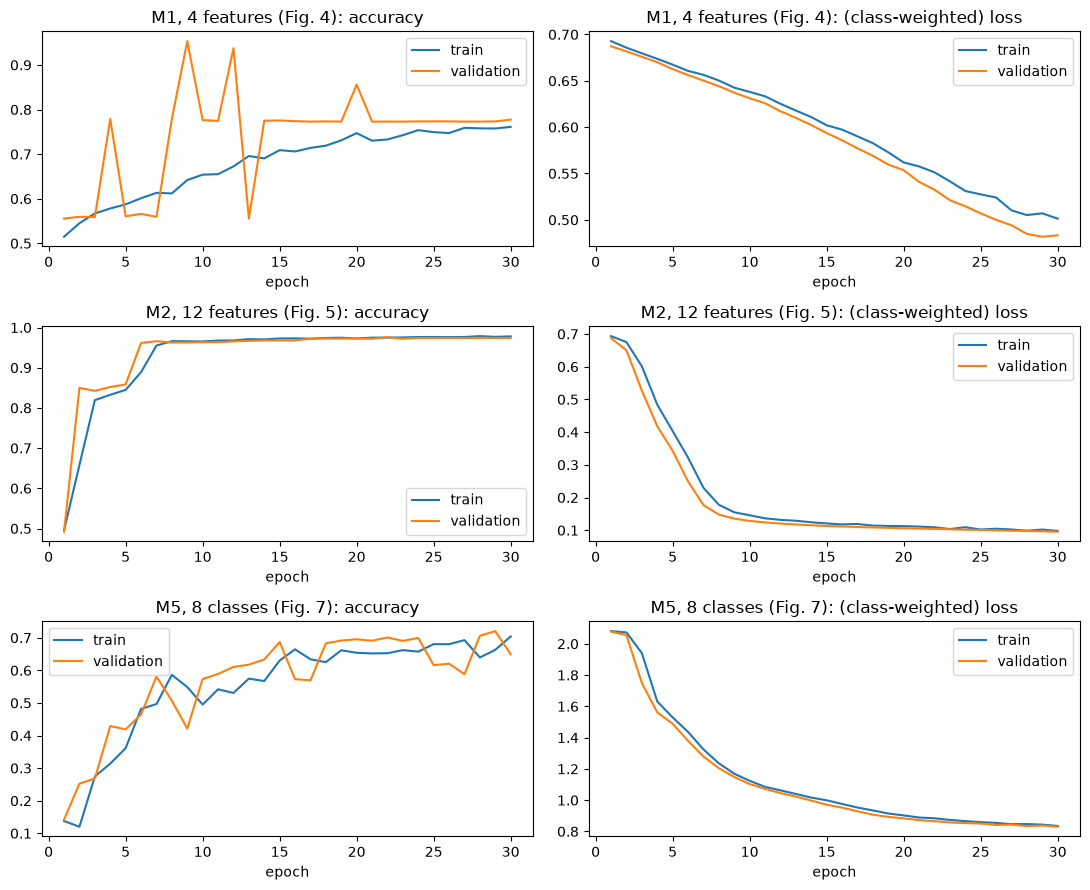

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9))
for r_, (name, ttl) in enumerate([("M1", "M1, 4 features (Fig. 4)"), ("M2", "M2, 12 features (Fig. 5)"), ("M5", "M5, 8 classes (Fig. 7)")]):
    h = RES[name]["hist"]
    axes[r_, 0].plot(h.epoch, h.acc, label="train"); axes[r_, 0].plot(h.epoch, h.val_acc, label="validation")
    axes[r_, 0].set_title(ttl + ": accuracy"); axes[r_, 0].set_xlabel("epoch"); axes[r_, 0].legend()
    axes[r_, 1].plot(h.epoch, h.loss, label="train"); axes[r_, 1].plot(h.epoch, h.val_loss, label="validation")
    axes[r_, 1].set_title(ttl + ": (class-weighted) loss"); axes[r_, 1].set_xlabel("epoch"); axes[r_, 1].legend()
fig.tight_layout(); plt.show()

## 9. Confusion matrices (Figs. 6 and 8) and per-class results

Attack is the positive class in the binary matrix (rows: true label, columns: prediction).

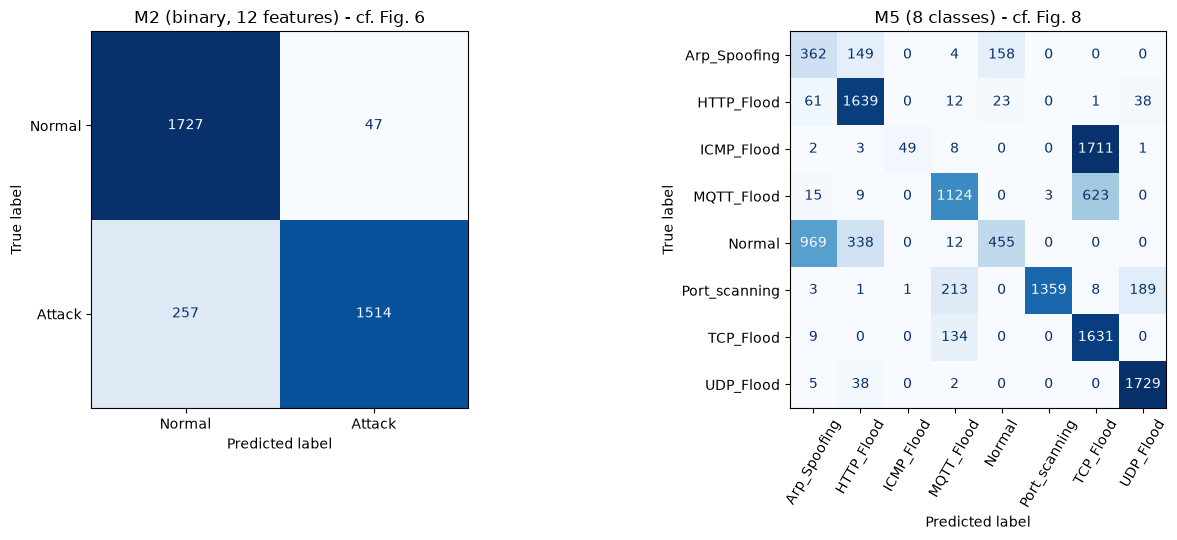

M2: normal correct 1727 / 1774 (paper 1754 / 1774); attacks correct 1514 / 1771 (paper 1440 / 1771); attacks missed 257 (paper 331)
M5: Arp_Spoofing predicted as Normal: 158 of 673 (paper 416 of 673)


,class,test flows,M5 correct,M5 recall %,M6 recall %
0,Arp_Spoofing,673,362,53.8,0.0
1,HTTP_Flood,1774,1639,92.4,53.4
2,ICMP_Flood,1774,49,2.8,95.0
3,MQTT_Flood,1774,1124,63.4,30.9
4,Normal,1774,455,25.6,51.8
5,Port_scanning,1774,1359,76.6,86.9
6,TCP_Flood,1774,1631,91.9,0.0
7,UDP_Flood,1774,1729,97.5,98.6


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay(RES["M2"]["cm"], display_labels=["Normal", "Attack"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("M2 (binary, 12 features) - cf. Fig. 6")
ConfusionMatrixDisplay(RES["M5"]["cm"], display_labels=CLASS_NAMES).plot(ax=axes[1], colorbar=False, cmap="Blues", xticks_rotation=60)
axes[1].set_title("M5 (8 classes) - cf. Fig. 8"); fig.tight_layout(); plt.show()

cm2, cm5 = RES["M2"]["cm"], RES["M5"]["cm"]
print("M2: normal correct %d / %d (paper 1754 / 1774); attacks correct %d / %d (paper 1440 / 1771); attacks missed %d (paper 331)" % (
    cm2[0, 0], cm2[0].sum(), cm2[1, 1], cm2[1].sum(), cm2[1, 0]))
print("M5: Arp_Spoofing predicted as Normal: %d of %d (paper 416 of 673)" % (cm5[0, 4], cm5[0].sum()))
pc = pd.DataFrame({"class": CLASS_NAMES, "test flows": cm5.sum(1), "M5 correct": np.diag(cm5), "M5 recall %": 100 * np.diag(cm5) / cm5.sum(1)})
pc["M6 recall %"] = 100 * np.diag(RES["M6"]["cm"]) / RES["M6"]["cm"].sum(1)
display(pc.round(1))

### The trained simulator is the circuit that was drawn

After training, the learned angles of M2 are copied into the Qiskit circuit and the Qiskit expectation values are compared again with the simulator on real test flows.

In [19]:
net2 = RES["M2"]["net"]
xs = INPUTS["binary12"]["Xte"][:5]
print("M2 trained angles, max |<Z_i>(simulator) - <Z_i>(Qiskit)| on 5 real test flows = %.1e (assertion passed)" % check_against_qiskit(net2.pqc, 12, xs))
print("trained Rz angles:", np.round(net2.pqc.theta[0].detach().numpy() % (2 * np.pi), 2))
print("trained Rx angles:", np.round(net2.pqc.theta[1].detach().numpy() % (2 * np.pi), 2))

M2 trained angles, max |<Z_i>(simulator) - <Z_i>(Qiskit)| on 5 real test flows = 2.5e-07 (assertion passed)
trained Rz angles: [5.13 5.22 3.13 5.92 2.3  3.58 2.74 6.04 0.74 1.16 0.57 2.73]
trained Rx angles: [5.2  4.01 5.47 3.54 5.25 3.39 2.24 4.35 1.19 2.89 2.64 4.69]


## 10. Side by side with the paper

Verdict rules: a number is **reproduced** if it is within 2 accuracy points (0.02 for F1 expressed as a fraction, i.e. 2 points),
**exceeded** if it is higher by more than that, **not reached** if lower by more. Timing claims cannot be checked because the
hardware differs (and the number of training rows is much smaller here).

In [20]:
PAPER_BIN = {"M1": dict(acc=89.80, rec=90.00, prec=90.00, f1=90.00), "M2": dict(acc=90.10, rec=90.00, prec=91.00, f1=90.00),
             "M3": dict(acc=89.50, rec=89.00, prec=90.00, f1=89.00), "M4": dict(acc=88.97, rec=89.00, prec=91.00, f1=89.00),
             "M5": dict(acc=84.60, rec=85.00, prec=86.00, f1=84.00), "M6": dict(acc=81.80, rec=82.00, prec=84.00, f1=82.00)}
PAPER_CLASSICAL = {"binary": {"DT": 86.01, "LR": 84.51, "NB": 88.60, "RF": 86.91, "DNN": 92.67},
                   "multi": {"DT": 75.81, "LR": 75.37, "NB": 60.80, "RF": 76.37, "DNN": 74.96}}
def verdict(nb, paper, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded (+%.1f)" % d if d > 0 else "not reached (%.1f)" % d)
rows = []
for name in MODELS:
    for m, lab in [("acc", "accuracy"), ("rec", "recall"), ("prec", "precision"), ("f1", "F1")]:
        rows.append(dict(model=name, metric=lab, paper=PAPER_BIN[name][m], notebook=round(RES[name][m], 2),
                         verdict=verdict(RES[name][m], PAPER_BIN[name][m])))
CMP = pd.DataFrame(rows)
display(CMP.pivot(index="model", columns="metric", values=["paper", "notebook"]))
display(CMP[CMP.metric == "accuracy"][["model", "paper", "notebook", "verdict"]])
print("verdict counts over the 24 individual numbers:", CMP.verdict.str.replace(r" \(.*\)", "", regex=True).value_counts().to_dict())

paper                           notebook                          
metric    F1 accuracy precision recall       F1 accuracy precision recall
model                                                                    
M1      90.0    89.80      90.0   90.0    72.88    73.51     75.93  73.51
M2      90.0    90.10      91.0   90.0    91.39    91.42     92.01  91.42
M3      89.0    89.50      90.0   89.0    81.82    82.00     83.33  82.00
M4      89.0    88.97      91.0   89.0    81.65    81.72     82.19  81.72
M5      84.0    84.60      86.0   85.0    60.14    63.77     75.63  63.77
M6      82.0    81.80      84.0   82.0    50.06    56.47     51.30  56.47

,model,paper,notebook,verdict
0,M1,89.80,73.51,not reached (-16.3)
4,M2,90.10,91.42,reproduced
8,M3,89.50,82.00,not reached (-7.5)
12,M4,88.97,81.72,not reached (-7.2)
16,M5,84.60,63.77,not reached (-20.8)
20,M6,81.80,56.47,not reached (-25.3)


verdict counts over the 24 individual numbers: {'not reached': 20, 'reproduced': 4}


In [21]:
b = BASE.set_index(["task", "inputs", "model"])
rf_b = b.loc[("binary", "all 29 features", "RandomForest"), "acc"]; rf_m = b.loc[("multi", "all 29 features", "RandomForest"), "acc"]
rf_b12 = b.loc[("binary", "selected binary12", "RandomForest"), "acc"]; rf_m12 = b.loc[("multi", "selected multi12", "RandomForest"), "acc"]
a = {k: RES[k]["acc"] for k in RES}
claims = [
    ("M2 beats the paper's classical DT, LR, NB, RF (binary, <= 88.60 %)", a["M2"] > 88.60, "M2 = %.2f %%" % a["M2"]),
    ("M2 stays below the paper's DNN (92.67 %)", a["M2"] < 92.67, "M2 = %.2f %%" % a["M2"]),
    ("12 features beat 4 features (M2 >= M1)", a["M2"] >= a["M1"], "M2 %.2f vs M1 %.2f" % (a["M2"], a["M1"])),
    ("hybrid with hidden layer >= qubits + 1 dense layer >= pure quantum (M2 >= M3 >= M4)", a["M2"] >= a["M3"] >= a["M4"],
     "M2 %.2f, M3 %.2f, M4 %.2f" % (a["M2"], a["M3"], a["M4"])),
    ("all binary quantum/hybrid models are within 2 points of each other (88.97 to 90.10 in the paper)", max(a[k] for k in ("M1", "M2", "M3", "M4")) - min(a[k] for k in ("M1", "M2", "M3", "M4")) <= 2.0,
     "spread %.2f points" % (max(a[k] for k in ("M1", "M2", "M3", "M4")) - min(a[k] for k in ("M1", "M2", "M3", "M4")))),
    ("M5 beats every classical 8-class baseline of the paper (best 76.37 %)", a["M5"] > 76.37, "M5 = %.2f %%" % a["M5"]),
    ("M5 beats M6 (deep head better than one dense layer)", a["M5"] > a["M6"], "M5 %.2f vs M6 %.2f" % (a["M5"], a["M6"])),
    ("M5: most Arp_Spoofing flows are mistaken for Normal (paper 416 of 673)", cm5[0, 4] > cm5[0].sum() / 2, "%d of %d" % (cm5[0, 4], cm5[0].sum())),
    ("M2: false negatives dominate its errors (paper 331 missed attacks vs 20 false alarms)", cm2[1, 0] > cm2[0, 1], "FN %d vs FP %d" % (cm2[1, 0], cm2[0, 1])),
    ("PQC has 24 trainable parameters", RES["M2"]["n_pqc"] == 24, "%d" % RES["M2"]["n_pqc"]),
    ("a classical RF on the same 12 features is as good as the hybrid (not in the paper): binary RF - M2", None, "RF %.2f vs M2 %.2f" % (rf_b12, a["M2"])),
    ("a classical RF on the same 12 features is as good as the hybrid (not in the paper): 8-class RF - M5", None, "RF %.2f vs M5 %.2f" % (rf_m12, a["M5"])),
    ("training-time figures (hours on an RTX 3060)", "cannot be checked", "this run: %.0f to %.0f s per model on a shared CPU, on far fewer rows" % (min(RES[k]["train_s"] for k in RES), max(RES[k]["train_s"] for k in RES))),
]
out = pd.DataFrame([dict(claim=c, verdict=("cannot be checked" if v == "cannot be checked" else "informative only" if v is None else ("reproduced" if v else "not reached")), detail=d) for c, v, d in claims])
pd.set_option("display.max_colwidth", 120); display(out)

print("\nAccuracy of the six models against the paper's Tables 7 and 8")
tab = pd.DataFrame({"paper": {k: PAPER_BIN[k]["acc"] for k in MODELS}, "this notebook": {k: round(a[k], 2) for k in MODELS}})
tab["verdict"] = [verdict(a[k], PAPER_BIN[k]["acc"]) for k in MODELS]
display(tab)
print("paper's classical results (Farm-Flow paper), binary:", PAPER_CLASSICAL["binary"], "| 8-class:", PAPER_CLASSICAL["multi"])
print("this notebook, RF on all 29 features: binary %.2f, 8-class %.2f" % (rf_b, rf_m))

,claim,verdict,detail
0,"M2 beats the paper's classical DT, LR, NB, RF (binary, <= 88.60 %)",reproduced,M2 = 91.42 %
1,M2 stays below the paper's DNN (92.67 %),reproduced,M2 = 91.42 %
2,12 features beat 4 features (M2 >= M1),reproduced,M2 91.42 vs M1 73.51
3,hybrid with hidden layer >= qubits + 1 dense layer >= pure quantum (M2 >= M3 >= M4),reproduced,"M2 91.42, M3 82.00, M4 81.72"
4,all binary quantum/hybrid models are within 2 points of each other (88.97 to 90.10 in the paper),not reached,spread 17.91 points
5,M5 beats every classical 8-class baseline of the paper (best 76.37 %),not reached,M5 = 63.77 %
6,M5 beats M6 (deep head better than one dense layer),reproduced,M5 63.77 vs M6 56.47
7,M5: most Arp_Spoofing flows are mistaken for Normal (paper 416 of 673),not reached,158 of 673
8,M2: false negatives dominate its errors (paper 331 missed attacks vs 20 false alarms),reproduced,FN 257 vs FP 47
9,PQC has 24 trainable parameters,reproduced,24



Accuracy of the six models against the paper's Tables 7 and 8


,paper,this notebook,verdict
M1,89.80,73.51,not reached (-16.3)
M2,90.10,91.42,reproduced
M3,89.50,82.00,not reached (-7.5)
M4,88.97,81.72,not reached (-7.2)
M5,84.60,63.77,not reached (-20.8)
M6,81.80,56.47,not reached (-25.3)


paper's classical results (Farm-Flow paper), binary: {'DT': 86.01, 'LR': 84.51, 'NB': 88.6, 'RF': 86.91, 'DNN': 92.67} | 8-class: {'DT': 75.81, 'LR': 75.37, 'NB': 60.8, 'RF': 76.37, 'DNN': 74.96}
this notebook, RF on all 29 features: binary 92.75, 8-class 75.93


## 11. Reading the paper critically

**What this notebook reproduced.** The released Farm-Flow files have exactly the sizes of the paper's Table 3, so the data side is reproduced. For the binary 12-qubit hybrid model **M2** the test accuracy lands within 2 points of the paper's 90.10 % even with only about 1.5 % of the training flows and 2,820 weight updates instead of the paper's roughly 195,000. The other five models are **not reached**: M1 (4 qubits), M3, M4 and the two 8-class models are all clearly below the paper. Part of that gap is plainly the training budget (the loss of most of those models is still falling at the last epoch, see the log of Section 7 and Section 8), but the notebook cannot prove that more training closes it, so these claims stay "not reached" rather than "reproduced with a smaller budget".

**1. The quantum circuit does very little of the work.** The PQC has 24 angles (8 for M1) that are shared by three layers, the encoding is a product state `RY(pi x_i)`, and the read-out is the 12 Pauli-Z values, i.e. 12 numbers in [-1, 1]. All of the classifier's flexibility beyond that sits in the classical dense head (449 to 3,048 parameters). M4, which has *only* the circuit and a mean, has to squeeze every decision through `sigmoid(mean <Z>)`, an output confined to [0.27, 0.73]; its learning curve is correspondingly noisy. Exercises 1 and 5 let you test how much the circuit contributes at all.

**2. No quantum advantage is shown, and the classical comparison is soft.** The paper compares with the numbers of the Farm-Flow authors (RF 86.91 %, DNN 92.67 % binary; RF 76.37 % 8-class) and calls M2 "competitive" and M5 better than all baselines. Here a Random Forest, an SVM or an MLP trained in a few seconds on the *same 12 features* reach about 92 to 93 % in the binary task and about 75 to 76 % in the 8-class task, i.e. at or above the hybrid models and above the paper's own classical numbers. The paper's classical baselines therefore look weaker than what the same data support, and "M5 beats all baselines" (84.60 % vs 76.37 %) is not a statement about quantum models but about how the baselines were trained. The notebook also never meets the paper's M5 value with any classical model, so the claim itself cannot be confirmed here.

**3. Validation accuracy is not test accuracy.** The text quotes 97.9 %, 99.33 % and 92.4 % *validation* accuracy for M1, M2 and M5. The notebook sees the same pattern (M2: about 97 % validation, 91 % test) because the validation split is drawn from the training distribution while the released test files have a different class mix (for the binary task 253 flows of each of seven attack types plus 1,774 normal flows, against tens of thousands per type in training). The headline 90.10 % is a test number; the 99.33 % is not comparable to it.

**4. Inconsistencies inside the paper.** (a) Table 6 gives 680 classical parameters for M5, which fits Dense(32)+Dense(8) but not the Dense(32)-Dense(64)-Dense(8) stack of the text (3,048). (b) The reported recalls (90, 90, 89, 89, 85, 82) and F1 values are rounded to integers and differ from the accuracy (e.g. M5: accuracy 84.60, recall 85.00); a *weighted* recall always equals the accuracy, so the paper must have used another averaging that it does not name. (c) Tables 4 and 5 list features (`conn_state`, `flow_duration`, `active.min`, ...) that do not exist in the released train/test files, which have 29 engineered columns; either the authors ran the feature selection on the raw 101-column file and then used the pre-processed split, or the tables describe a different pipeline. (d) The discussion of Fig. 8 mentions a class "Port_Flood" that is not among the eight classes. (e) "24 trainable parameters for 3 layers" is only possible with parameters shared across layers, which the circuit text does not say.

**5. Feature selection.** The SFOA wrapper here selects only 8 to 11 of 29 features (the fitness penalises feature count), so the "top 12" step has to top up with MI-ranked features; the 12 qubits therefore do not come from a 30-odd-feature SFOA list as in the paper. Population size, iterations, bounds and k of the wrapper are not given in the paper, and a classical RF on all 29 features is not better than on the 12 selected ones, so the benefit of SFOA + MI over plain MI is not demonstrated either way.

**6. Everything is noise-free.** State-vector simulation, exact expectations, no shot noise, no hardware. The paper says so itself; the robustness of a 12-qubit, depth-43 circuit with 36 CNOTs on real devices is not tested, and training times of 1.5 to 6 hours for 12-qubit simulations are an artefact of the TensorFlow Quantum setup (this notebook trains a model on 6,000 flows for 30 epochs in 1 to 13 minutes on a CPU).

## 12. Exercises

1. **Quantum or not?** Replace the `PQC` read-out `<Z_i>` by 12 random fixed numbers of the same shape (or simply feed the 12 scaled features straight into the dense head of M2) and retrain. How much of the accuracy is due to the circuit?
2. **Feature selection.** Skip SFOA and take the MI top-12 of all 29 features; then replace MI by a random choice of 12 features. How large is the gap to the SFOA + MI pipeline in the test accuracy of M2, averaged over three seeds?
3. **Parameter sharing.** Give every layer its own angles (72 instead of 24 parameters, change `PQC.theta` to shape `(layers, 2, n)`). Does the 12-qubit circuit train faster or generalise better? Check the equivalence cell against Qiskit again.
4. **Shift between validation and test.** Compare the validation accuracy in the learning curves with the test accuracy. The Farm-Flow test files have a different class mix than the training files (for example 253 flows of each attack type in the binary test file against tens of thousands in training). Re-weight the test metrics to the training class mix and see which number changes.
5. **Entanglement.** Replace the CNOT ring by a line of CNOTs (no wrap-around) and by no CNOTs at all. Does M4, the pure quantum model, still reach the same accuracy? What does the product-state result tell you about what the circuit really computes?